# Deep Neural Network - Baseline - > Regularization

In [ ]:
# import library
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

import tensorflow as tf
from tensorflow import keras


In [ ]:
# environment check
tf.__version__

'2.20.0'

In [ ]:
# gpu
tf.config.list_physical_devices()

[PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]

In [ ]:
import torch

In [ ]:
# check for GPU
print(torch.cuda.is_available())


False


In [ ]:
# no GPU - by default is CPU
tf.config.list_physical_devices('GPU')

[]

In [ ]:
# recheck GPU
import tensorflow as tf
tf.test.gpu_device_name()

'/device:GPU:0'

In [ ]:
# pytorch
import torch
torch.cuda.is_available()

True

In [ ]:
# device name
torch.cuda.get_device_name()

'Tesla T4'

## 1. load the data


In [ ]:
(X_train, y_train), (X_test, y_test) = keras.datasets.fashion_mnist.load_data()
# print shape
print(X_train.shape, y_train.shape, X_test.shape, y_test.shape)
# see one image
X_train[0]

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
(60000, 28, 28) (60000,) (10000, 28, 28) (10000,)


array([[  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   1,
          0,   0,  13,  73,   0,   0,   1,   4,   0,   0,   0,   0,   1,
          1,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   3,
          0,  36, 136, 127,  62,  54,   0,   0,   0,   1,   3,   4,   0,
          0,   3],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   6,
          0, 102, 204, 176, 134, 144, 123,  23,   0,   0,   0,   0,  12,
         10,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0, 155, 236, 207, 178, 107, 156, 161, 109,  64,  23,  77, 130,
         72,  15],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   1,   0,
         69, 207, 223, 218, 216, 216, 163, 127, 121, 122, 146, 141,  88,
        172,  66],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   1,   1,   1,   0,
        200, 232, 232, 233, 229, 223, 223, 215, 213, 164, 127, 123, 196,
        229,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
        183, 225, 216, 223, 228, 235, 227, 224, 222, 224, 221, 223, 245,
        173,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
        193, 228, 218, 213, 198, 180, 212, 210, 211, 213, 223, 220, 243,
        202,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   1,   3,   0,  12,
        219, 220, 212, 218, 192, 169, 227, 208, 218, 224, 212, 226, 197,
        209,  52],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   6,   0,  99,
        244, 222, 220, 218, 203, 198, 221, 215, 213, 222, 220, 245, 119,
        167,  56],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   4,   0,   0,  55,
        236, 228, 230, 228, 240, 232, 213, 218, 223, 234, 217, 217, 209,
         92,   0],
       [  0,   0,   1,   4,   6,   7,   2,   0,   0,   0,   0,   0, 237,
        226, 217, 223, 222, 219, 222, 221, 216, 223, 229, 215, 218, 255,
         77,   0],
       [  0,   3,   0,   0,   0,   0,   0,   0,   0,  62, 145, 204, 228,
        207, 213, 221, 218, 208, 211, 218, 224, 223, 219, 215, 224, 244,
        159,   0],
       [  0,   0,   0,   0,  18,  44,  82, 107, 189, 228, 220, 222, 217,
        226, 200, 205, 211, 230, 224, 234, 176, 188, 250, 248, 233, 238,
        215,   0],
       [  0,  57, 187, 208, 224, 221, 224, 208, 204, 214, 208, 209, 200,
        159, 245, 193, 206, 223, 255, 255, 221, 234, 221, 211, 220, 232,
        246,   0],
       [  3, 202, 228, 224, 221, 211, 211, 214, 205, 205, 205, 220, 240,
         80, 150, 255, 229, 221, 188, 154, 191, 210, 204, 209, 222, 228,
        225,   0],
       [ 98, 233, 198, 210, 222, 229, 229, 234, 249, 220, 194, 215, 217,
        241,  65,  73, 106, 117, 168, 219, 221, 215, 217, 223, 223, 224,
        229,  29],
       [ 75, 204, 212, 204, 193, 205, 211, 225, 216, 185, 197, 206, 198,
        213, 240, 195, 227, 245, 239, 223, 218, 212, 209, 222, 220, 221,
        230,  67],
       [ 48, 203, 183, 194, 213, 197, 185, 190, 194, 192, 202, 214, 219,
        221, 220, 236, 225, 216, 199, 206, 186, 181, 177, 172, 181, 205,
        206, 115],
       [  0, 122, 219, 193, 179, 171, 183, 196, 204, 210, 213, 207, 211,
        210, 200, 196, 194, 191, 195, 191, 198, 192, 176, 156, 167, 177,
        210,  92],
       [  0,   0,  74, 189, 212, 191, 175, 172, 175, 181, 185, 188, 189,
        188, 193, 198, 204, 209, 210, 210, 211, 188, 188, 194, 192, 216,
        170,   0],
       [  2,   0,   0,   0,  66, 200, 22

In [ ]:
y_train[0]

np.uint8(9)

## 2. Preprocess the data

In [ ]:
# flatten - mandatory
X_train = X_train.reshape(-1, 28*28)
# X_train = X_train.reshape(60000,784)

X_test = X_test.reshape(-1, 28*28)

# shape
print(X_train.shape, y_train.shape, X_test.shape, y_test.shape)
#

(60000, 784) (60000,) (10000, 784) (10000,)


In [ ]:
# normalization - optional
X_train = X_train / 255.0
X_test = X_test / 255.0

# check for one-input
X_train[0]

array([0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.     

## 3. Building a Simple ANN/DNN

- 784 = input-features(not neurons)
- 128 = hidden-layer neurons
- 10  = output neurons/classes

In [ ]:

simple_dnn = keras.models.Sequential(name="Baseline")

# layers
simple_dnn.add(keras.layers.Dense(units=128, activation='relu', input_shape=(784,)))
simple_dnn.add(keras.layers.Dense(units=10, activation='softmax'))

simple_dnn.summary()

Model: "Baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_6 (Dense)                 │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

- **Width : neurons in a layer =             128,10**
- **Depth : number of hidden layers =          1**

In [ ]:
# complile
# compile
simple_dnn.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

# fit
simple_dnn.fit(X_train, y_train, epochs=20, batch_size = 128, validation_split=0.2)

Epoch 1/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.8063 - loss: 0.5694 - val_accuracy: 0.8478 - val_loss: 0.4422
Epoch 2/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.8560 - loss: 0.4149 - val_accuracy: 0.8604 - val_loss: 0.3971
Epoch 3/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.8676 - loss: 0.3755 - val_accuracy: 0.8686 - val_loss: 0.3785
Epoch 4/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.8764 - loss: 0.3464 - val_accuracy: 0.8766 - val_loss: 0.3543
Epoch 5/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.8834 - loss: 0.3261 - val_accuracy: 0.8722 - val_loss: 0.3555
Epoch 6/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.8898 - loss: 0.3088 - val_accuracy: 0.8809 - val_loss: 0.3324
Epoch 7/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.8943 - loss: 0.2959 - val_accuracy: 0.8812 - val_loss: 0.3320
Epoch 8/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy: 0.8963 - loss: 0.2854 - val_accuracy: 0

In [ ]:
#test
simple_dnn.evaluate(X_test, y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8735 - loss: 0.3602


[0.36019250750541687, 0.8734999895095825]

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8735 - loss: 0.3602


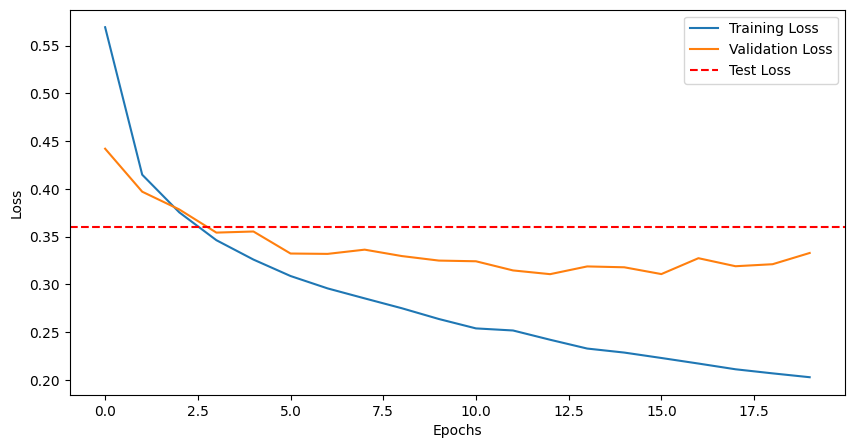

In [ ]:
# detection of Overfitting - Training vs Validation vs Test Loss
plt.figure(figsize=(10,5))
plt.plot(simple_dnn.history.history['loss'], label='Training Loss')
plt.plot(simple_dnn.history.history['val_loss'], label='Validation Loss')
plt.axhline(simple_dnn.evaluate(X_test, y_test)[0], color='red', linestyle='--', label='Test Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

#### Observations-
- `Classic Overfitting pattern` :  Training is reducing loss metric while Validation has reached a stale point.
- `No Generalization` : Testing has shown that no further than 3rd Epoch result is being learnt by model.

## Regularization

### Early Stopping
`monitor = 'val_loss`

In [ ]:
early_stop = keras.callbacks.EarlyStopping(
                                          monitor='val_loss',
                                          patience=5,
                                          restore_best_weights=True)

In [ ]:
# model
early_model = keras.Sequential(name="Early_Stopping")
early_model.add(keras.layers.Dense(units=128, activation='relu', input_shape=(784,)))
early_model.add(keras.layers.Dense(units=10, activation='softmax'))
early_model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

# fit
early_model.fit(X_train, y_train, epochs=50, batch_size=128,
                validation_split=0.2,
                callbacks=[early_stop])

Epoch 1/50
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.8037 - loss: 0.5750 - val_accuracy: 0.8438 - val_loss: 0.4392
Epoch 2/50
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8518 - loss: 0.4251 - val_accuracy: 0.8565 - val_loss: 0.4153
Epoch 3/50
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8664 - loss: 0.3810 - val_accuracy: 0.8668 - val_loss: 0.3753
Epoch 4/50
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8749 - loss: 0.3533 - val_accuracy: 0.8686 - val_loss: 0.3697
Epoch 5/50
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8827 - loss: 0.3311 - val_accuracy: 0.8733 - val_loss: 0.3666
Epoch 6/50
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8864 - loss: 0.3175 - val_accuracy: 0.8734 - val_loss: 0.3552
Epoch 7/50
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8904 - loss: 0.3050 - val_accuracy: 0.8792 - val_loss: 0.3374
Epoch 8/50
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8939 - loss: 0.2909 - val_accuracy: 0.

Stopped @ Epoch : 12, after waiting for next 5 epochs in patience.

In [ ]:
# best paramters as per EarlyStopping
test_acc, test_loss = early_model.evaluate(X_test, y_test)

# find the epoch number and validation accuracy
print("Minimum validation loss : ",min(early_model.history.history['val_loss']))

print("Test Loss @ best_params / lowest_val_loss :", test_loss)
print("Test Accuracy @ best_params / lowest_val_loss :", test_acc)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8771 - loss: 0.3400
Minimum validation loss :  0.3132854104042053
Test Loss @ best_params / lowest_val_loss : 0.8770999908447266
Test Accuracy @ best_params / lowest_val_loss : 0.3399743139743805


**`Observation` : Early Stopping reduced training time, got the best parameter state that produced least validation error.**


313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8771 - loss: 0.3400


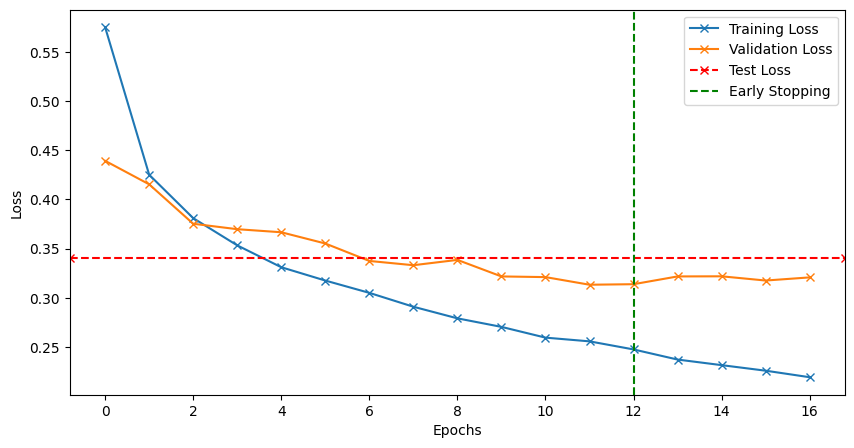

In [ ]:
# plot this loss of train,test,validation
plt.figure(figsize=(10,5))
plt.plot(early_model.history.history['loss'],marker = 'x', label='Training Loss')
plt.plot(early_model.history.history['val_loss'],marker = 'x', label='Validation Loss')
plt.axhline(early_model.evaluate(X_test, y_test)[0], color='red',marker = 'x', linestyle='--', label='Test Loss')
plt.axvline(x=12, color='green', linestyle='--', label='Early Stopping')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()


## Regularization with L2 - Ridge / Weight Decay

$ Loss_R = Loss_o + λ . ∑W^2$

In [ ]:
l2_model = keras.Sequential(name="L2_Regularization")

l2_model.add(keras.layers.Dense(units = 128, activation='relu', input_shape=(784,),
             kernel_regularizer=keras.regularizers.l2(0.01)))

l2_model.add(keras.layers.Dense(units = 10, activation='softmax'))

In [ ]:
l2_model.summary()

Model: "L2_Regularization"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_12 (Dense)                │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# weights
for layer in l2_model.layers:
    weights, biases = layer.get_weights()
    print(weights.shape)
    print(biases.shape)

    print(weights[:1])
    print(biases[:1])

(784, 128)
(128,)
[[ 8.07867572e-02  3.41262594e-02 -4.99056131e-02 -7.05736727e-02
  -7.24640340e-02  4.49418649e-02 -5.28138056e-02 -1.45331025e-02
   5.71574271e-03 -5.24102896e-03 -3.19984667e-02 -6.11749142e-02
   2.52576917e-02  2.22115666e-02 -9.80074704e-03 -7.59922117e-02
   7.24329874e-02 -5.11080138e-02  4.63805571e-02  1.61448717e-02
   9.21048224e-04  6.35499135e-02 -3.64498906e-02  4.87699732e-02
  -4.77779657e-03 -6.19805083e-02  1.52081773e-02 -1.72404051e-02
  -3.72501686e-02  7.54787028e-03 -1.25059411e-02 -1.11769959e-02
  -5.51231056e-02  7.81198516e-02 -4.38512787e-02  7.12473318e-02
   2.49038264e-02 -4.43253368e-02 -6.81717992e-02 -1.45288259e-02
   1.36030018e-02  5.65310195e-02 -1.61575377e-02  7.87195042e-02
  -3.87665033e-02 -4.60057370e-02 -1.17053762e-02  5.65217510e-02
  -1.90623216e-02  2.46238410e-02 -1.41670853e-02 -7.01121241e-02
   3.07930484e-02  5.45183569e-03 -9.62764770e-03 -4.62038405e-02
  -3.65207456e-02 -6.79192394e-02  2.33603790e-02 -4.21503

In [ ]:
# compile
l2_model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

# fit
l2_model.fit(X_train,y_train, epochs=20, batch_size=128, validation_split=0.2)

Epoch 1/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.7879 - loss: 1.2429 - val_accuracy: 0.8234 - val_loss: 0.6976
Epoch 2/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.8241 - loss: 0.6468 - val_accuracy: 0.8286 - val_loss: 0.6115
Epoch 3/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.8286 - loss: 0.6041 - val_accuracy: 0.8053 - val_loss: 0.6343
Epoch 4/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.8299 - loss: 0.5859 - val_accuracy: 0.8258 - val_loss: 0.6054
Epoch 5/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.8344 - loss: 0.5723 - val_accuracy: 0.8247 - val_loss: 0.5969
Epoch 6/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.8358 - loss: 0.5654 - val_accuracy: 0.8267 - val_loss: 0.5751
Epoch 7/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.8394 - loss: 0.5502 - val_accuracy: 0.8405 - val_loss: 0.5435
Epoch 8/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.8404 - loss: 0.5437 - val_accuracy: 0.

In [ ]:
# evaluate
l2_model.evaluate(X_test, y_test)


313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8299 - loss: 0.5467


[0.5467330813407898, 0.8299000263214111]

**Loss is more becasue penalty is larger @ 0.01, we can reduce it further for better loss/accuracy**

In [ ]:
# weights
for layer in l2_model.layers:
    weights, biases = layer.get_weights()
    print(weights.shape)
    print(biases.shape)

    print(weights[:1])
    print(biases[:1])

(784, 128)
(128,)
[[-2.68336432e-35  1.34120796e-07 -9.69491651e-08  9.71964073e-06
  -7.25493532e-35  9.00601904e-09 -3.15290016e-08  2.37930180e-07
   1.02023812e-04 -1.08655455e-04 -1.19329252e-05 -4.06250501e-16
   3.49961841e-34 -1.69413266e-04  8.00465727e-07 -4.89494353e-34
  -3.69326182e-34 -4.28941808e-27  1.09783385e-33 -5.09730235e-05
  -2.05204701e-15 -1.64634343e-06  8.84442998e-05  3.11271822e-34
  -4.25008864e-07  9.88168949e-07  8.01721253e-05 -1.07070955e-04
   7.52926496e-07  1.20622889e-19 -4.51761581e-34  3.37366764e-05
  -5.24995048e-05  2.76057960e-07 -4.20746892e-06  2.77845684e-05
  -4.14998212e-05  6.53552997e-05 -1.67363891e-04  1.32230343e-06
  -1.15372059e-04  2.20058420e-34  1.31352422e-08  1.17855932e-04
  -1.20742516e-04 -3.10913369e-04  1.29483233e-05 -4.60237881e-12
   3.93562213e-34  9.45767533e-05  1.96345226e-07 -5.06672586e-05
   1.33610069e-04 -6.04510242e-05 -2.46478021e-06 -2.54270338e-09
   9.34912407e-07 -3.02780621e-34 -6.06462199e-05 -3.17316

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8299 - loss: 0.5467


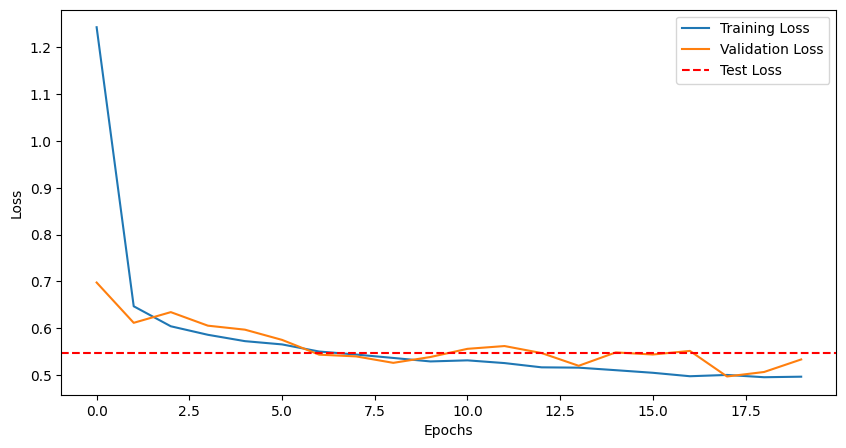

In [ ]:
# plot
plt.figure(figsize=(10,5))
plt.plot(l2_model.history.history['loss'], label='Training Loss')
plt.plot(l2_model.history.history['val_loss'], label='Validation Loss')
plt.axhline(l2_model.evaluate(X_test, y_test)[0], color='red', linestyle='--', label='Test Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

In [ ]:
# Multi - layer ANN with l2 regularizers
multi_layer = keras.Sequential(name="Multi_Layer_Model")

multi_layer.add(keras.layers.Dense(units = 64, activation='relu', input_shape=(784,),
             kernel_regularizer=keras.regularizers.l2(0.001)))
multi_layer.add(keras.layers.Dense(units = 32, activation='relu',
             kernel_regularizer=keras.regularizers.l2(0.001)))
multi_layer.add(keras.layers.Dense(units = 32, activation='relu',
             kernel_regularizer=keras.regularizers.l2(0.001)))

multi_layer.add(keras.layers.Dense(units = 10, activation='softmax'))

multi_layer.summary()
#

Model: "Multi_Layer_Model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_6 (Dense)                 │ (None, 64)             │        50,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 53,706 (209.79 KB)

 Trainable params: 53,706 (209.79 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# compile and fit
multi_layer.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

# fit
multi_layer.fit(X_train,y_train, epochs=20, batch_size=128, validation_split=0.2)

Epoch 1/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - accuracy: 0.7744 - loss: 0.8349 - val_accuracy: 0.8225 - val_loss: 0.6447
Epoch 2/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8444 - loss: 0.5806 - val_accuracy: 0.8437 - val_loss: 0.5732
Epoch 3/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8556 - loss: 0.5347 - val_accuracy: 0.8575 - val_loss: 0.5274
Epoch 4/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8625 - loss: 0.5036 - val_accuracy: 0.8663 - val_loss: 0.4964
Epoch 5/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8691 - loss: 0.4813 - val_accuracy: 0.8687 - val_loss: 0.4862
Epoch 6/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8698 - loss: 0.4745 - val_accuracy: 0.8568 - val_loss: 0.4979
Epoch 7/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8753 - loss: 0.4551 - val_accuracy: 0.8602 - val_loss: 0.4954
Epoch 8/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8760 - loss: 0.4519 - val_accuracy: 0.

In [ ]:
# test
multi_layer.evaluate(X_test, y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8694 - loss: 0.4486


[0.4485810101032257, 0.8694000244140625]

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8694 - loss: 0.4486


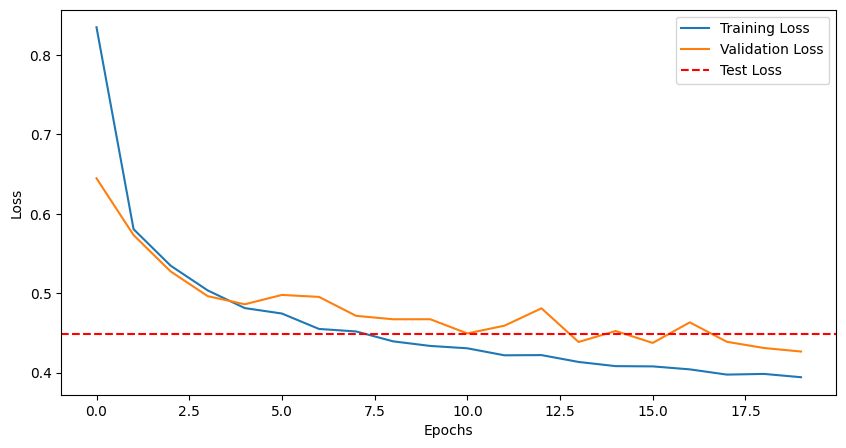

In [ ]:
# graph
plt.figure(figsize=(10,5))
plt.plot(multi_layer.history.history['loss'], label='Training Loss')
plt.plot(multi_layer.history.history['val_loss'], label='Validation Loss')
plt.axhline(multi_layer.evaluate(X_test, y_test)[0], color='red', linestyle='--', label='Test Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

### Reguarization with Dropouts

In [ ]:
dropout_model = keras.Sequential(name="Dropout_Regularization")

dropout_model.add(keras.layers.Dense(units = 128, activation='relu', input_shape=(784,)))
dropout_model.add(keras.layers.Dropout(0.5))

dropout_model.add(keras.layers.Dense(units = 10, activation='softmax'))

dropout_model.summary()



Model: "Dropout_Regularization"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_10 (Dense)                │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# compile
dropout_model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

# fit
dropout_model.fit(X_train,y_train, epochs=20, batch_size=128, validation_split=0.2)

Epoch 1/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.7450 - loss: 0.7335 - val_accuracy: 0.8373 - val_loss: 0.4661
Epoch 2/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8247 - loss: 0.5011 - val_accuracy: 0.8457 - val_loss: 0.4250
Epoch 3/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8372 - loss: 0.4575 - val_accuracy: 0.8574 - val_loss: 0.3919
Epoch 4/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8468 - loss: 0.4315 - val_accuracy: 0.8626 - val_loss: 0.3797
Epoch 5/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8516 - loss: 0.4155 - val_accuracy: 0.8675 - val_loss: 0.3649
Epoch 6/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8566 - loss: 0.3978 - val_accuracy: 0.8672 - val_loss: 0.3620
Epoch 7/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8606 - loss: 0.3889 - val_accuracy: 0.8728 - val_loss: 0.3513
Epoch 8/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8632 - loss: 0.3807 - val_accuracy: 0.

In [ ]:
# MODEL EVALUATE
dropout_model.evaluate(X_test, y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8774 - loss: 0.3529


[0.3528665602207184, 0.8773999810218811]

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8774 - loss: 0.3529


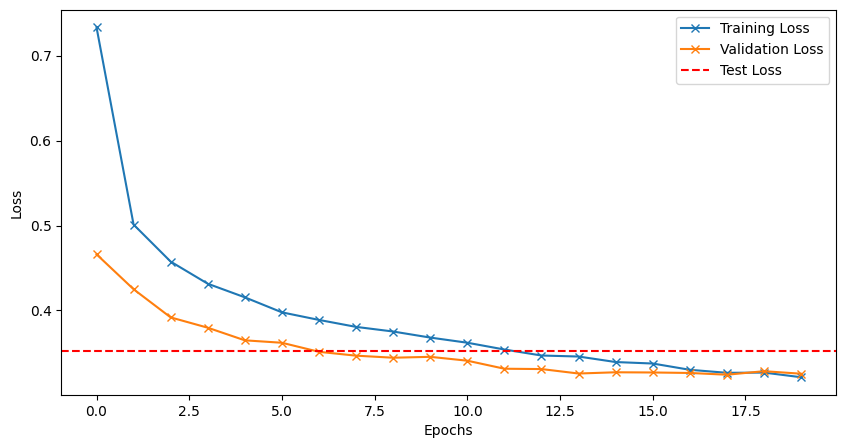

In [ ]:
# PLOT THEM
plt.figure(figsize=(10,5))
plt.plot(dropout_model.history.history['loss'],marker = 'x', label='Training Loss')
plt.plot(dropout_model.history.history['val_loss'],marker = 'x', label='Validation Loss')
plt.axhline(dropout_model.evaluate(X_test, y_test)[0], color='red', linestyle='--', label='Test Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()
#

## APPROACH TO MAKE MULTIPLE LAYERS WITH SAME NEURONS (128)
64->32->32


In [ ]:
# MULTI-LAYER MODEL
ann_model = keras.Sequential(name="Multi_Layer_Model")

ann_model.add(keras.layers.Dense(units = 64, activation='relu', input_shape=(784,)))
ann_model.add(keras.layers.Dense(units = 32, activation='relu'))
ann_model.add(keras.layers.Dense(units = 32, activation='relu'))

ann_model.add(keras.layers.Dense(units = 10, activation='softmax'))

ann_model.summary()

Model: "Multi_Layer_Model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_16 (Dense)                │ (None, 64)             │        50,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_18 (Dense)                │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_19 (Dense)                │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 53,706 (209.79 KB)

 Trainable params: 53,706 (209.79 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# complile
ann_model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

# fit
ann_model.fit(X_train,y_train, epochs=20, batch_size=128, validation_split=0.2)

Epoch 1/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.7701 - loss: 0.6532 - val_accuracy: 0.8322 - val_loss: 0.4747
Epoch 2/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.8487 - loss: 0.4295 - val_accuracy: 0.8477 - val_loss: 0.4232
Epoch 3/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.8607 - loss: 0.3883 - val_accuracy: 0.8598 - val_loss: 0.3864
Epoch 4/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8688 - loss: 0.3605 - val_accuracy: 0.8630 - val_loss: 0.3774
Epoch 5/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8760 - loss: 0.3399 - val_accuracy: 0.8683 - val_loss: 0.3688
Epoch 6/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8804 - loss: 0.3259 - val_accuracy: 0.8727 - val_loss: 0.3592
Epoch 7/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8859 - loss: 0.3113 - val_accuracy: 0.8774 - val_loss: 0.3462
Epoch 8/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8887 - loss: 0.3006 - val_accuracy: 0.

In [ ]:
# evaluate
ann_model.evaluate(X_test, y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8799 - loss: 0.3651


[0.3651203513145447, 0.8798999786376953]